# Beispiel 00_c - Schrittweise vorhersagen: ARMA und lineare Regression

**Was passiert, wenn nach jeder Vorhersage ein echter Messwert eintrifft?**

Wir verwenden dieselben künstlichen Verbrauchsdaten und denselben bekannten Produktionsplan wie in 00_b.
Dieses Notebook funktioniert eigenständig. Die Zellen von oben nach unten ausführen.

Wir vergleichen:

- ARMA mit Produktionsplan: alle 40 Tage am Stück vorhersagen.
- Dasselbe ARMA-Modell: jeden Tag einzeln vorhersagen und anschließend den echten Wert übernehmen.
- Eine normale lineare Regression mit dem Produktionsplan.

**Der Ablauf beim schrittweisen Vorhersagen:** Vorhersagen → messen → Zustand aktualisieren → nächsten Tag vorhersagen.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from statsmodels.tsa.arima.model import ARIMA

plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True,
                     "grid.alpha": 0.2, "font.size": 11})
from sklearn.linear_model import LinearRegression

Matplotlib is building the font cache; this may take a moment.


## 1. Daten vorbereiten

An Produktionstagen ist der Verbrauch höher. Zusätzlich gibt es kleine zeitlich zusammenhängende
Schwankungen. Der Produktionsplan ist vorab bekannt, die zukünftigen Verbrauchsmessungen nicht.

In [2]:
# Künstliche Daten: Der Plan gilt für alle 160 Tage bereits als festgelegt.
tage = pd.RangeIndex(1, 161, name="Tag")
produktion = pd.Series(0, index=tage, name="Produktion")
for start, ende in [(12, 25), (38, 50), (65, 78), (96, 108), (126, 137), (148, 157)]:
    produktion.loc[start:ende] = 1

# Kleine zeitlich zusammenhängende Schwankungen im Verbrauch.
rng = np.random.default_rng(42)
schocks = rng.normal(0, 0.15, len(tage))
rest = np.zeros(len(tage))
for i in range(1, len(tage)):
    rest[i] = 0.6 * rest[i-1] + schocks[i] + 0.3 * schocks[i-1]

verbrauch = pd.Series(20 + 8 * produktion.to_numpy() + rest, index=tage, name="Verbrauch")
merkmale = produktion.to_frame()

In [3]:
training = verbrauch.iloc[:120]
test = verbrauch.iloc[120:]
merkmale_training = merkmale.iloc[:120]
merkmale_zukunft = merkmale.iloc[120:]

## 2. Einmal lernen, danach vorhersagen

Wir lernen das ARMA-Modell nur aus den ersten 120 Tagen. `d=0` bedeutet keine Differenzierung.
`exog` übergibt den Produktionsplan. Wie in 00_b ist dies eine Regression mit ARMA-Fehlern:
Der Plan erklärt den Produktionsverbrauch, ARMA beschreibt die verbleibenden zeitlichen Abhängigkeiten.

In [4]:
modell = ARIMA(training, order=(1, 0, 1), exog=merkmale_training)
gelernt = modell.fit(method_kwargs={"maxiter": 1000})

# Vergleich: Alle 40 Werte am Ende von Tag 120 vorhersagen.
prognose_fest = gelernt.forecast(steps=40, exog=merkmale_zukunft)

## 3. Genau einen Tag vorhersagen

Wir stehen am Ende von Tag 120 und sagen Tag 121 vorher. Dafür geben wir genau eine Zeile des Plans mit.

`iloc[:1]` wählt die erste Zeile als Tabelle aus. `iloc[0]` holt danach aus der Prognose den ersten Zahlenwert.

In [5]:
zustand = gelernt
plan_tag_121 = merkmale_zukunft.iloc[:1]
prognose_tag_121 = zustand.forecast(steps=1, exog=plan_tag_121)
print(f"Vorhersage für Tag 121: {prognose_tag_121.iloc[0]:.3f} kWh")

Vorhersage für Tag 121: 20.079 kWh


## 4. Jetzt kommt der echte Messwert

Erst **nach** der Prognose lesen wir die tatsächliche Beobachtung für diesen Tag.
Die Abweichung ist die neue Überraschung aus Sicht unseres Modells, also eine Schätzung des Schocks.

In [6]:
messung_tag_121 = test.iloc[:1]
abweichung_tag_121 = messung_tag_121.iloc[0] - prognose_tag_121.iloc[0]
print(f"Tatsächlich gemessen: {messung_tag_121.iloc[0]:.3f} kWh")
print(f"Neue Vorhersageabweichung: {abweichung_tag_121:+.3f} kWh")

zustand = zustand.append(messung_tag_121, exog=plan_tag_121, refit=False)
print(f"Intern gespeichertes letztes Residuum: {zustand.resid.iloc[-1]:+.3f} kWh")

Tatsächlich gemessen: 19.932 kWh
Neue Vorhersageabweichung: -0.147 kWh
Intern gespeichertes letztes Residuum: -0.147 kWh


**Was macht `append`?** Die neue Beobachtung aktualisiert den internen Zustand.
Dadurch stehen der neue Messwert und die neue Vorhersageabweichung für die nächste Prognose zur Verfügung.

**`refit=False`:** Die gelernten Koeffizienten bleiben gleich. Es wird kein neues Modell trainiert.
Wir übernehmen das zurückgegebene Ergebnis wieder in `zustand`.

`resid` zeigt die Ein-Schritt-Vorhersageabweichungen. Das sind geschätzte Schocks,
nicht direkt beobachtbare „wahre“ Zufallsschocks.

## 5. Den darauffolgenden Tag vorhersagen

Jetzt kennen wir den echten Verbrauch von Tag 121. Für Tag 122 geben wir wieder nur den zugehörigen Plan mit.

In [7]:
plan_tag_122 = merkmale_zukunft.iloc[1:2]
prognose_tag_122 = zustand.forecast(steps=1, exog=plan_tag_122)

print(f"Tag 122, schon an Tag 120 vorhergesagt: {prognose_fest.iloc[1]:.3f} kWh")
print(f"Tag 122, nach der neuen Messung:       {prognose_tag_122.iloc[0]:.3f} kWh")
print(f"Gelernter MA-Faktor: {gelernt.params['ma.L1']:.3f}")

Tag 122, schon an Tag 120 vorhergesagt: 20.039 kWh
Tag 122, nach der neuen Messung:       19.907 kWh
Gelernter MA-Faktor: 0.304


**Was hat MA damit zu tun?** Die Abweichung von Tag 121 ist jetzt bekannt und kann beim nächsten
Schritt im MA-Anteil nachwirken. Ohne diese Messung wäre der Schock von Tag 121 unbekannt geblieben.

Auch der AR-Anteil verwendet den aktualisierten Zustand. Der Unterschied zwischen den beiden
Vorhersagen ist deshalb **nicht allein der MA-Effekt**.

Die Vorhersage selbst wird nicht als echte Beobachtung angehängt. Wir übernehmen ausschließlich Messwerte.

## 6. Dasselbe für alle 40 Tage wiederholen

Die Schleife macht genau das, was wir gerade einzeln ausgeführt haben.
Wir starten dafür noch einmal beim ursprünglichen Zustand am Ende von Tag 120.

In [8]:
zustand = gelernt
vorhersagen = []
protokoll = []

for i in range(len(test)):
    # 1. Nur den bereits bekannten Plan des nächsten Tages bereitstellen.
    plan = merkmale_zukunft.iloc[i:i+1]

    # 2. Vorhersagen, BEVOR der echte Verbrauch dieses Tages gelesen wird.
    prognose = zustand.forecast(steps=1, exog=plan)
    schaetzung = prognose.iloc[0]
    vorhersagen.append(schaetzung)

    # 3. Jetzt trifft die tatsächliche Messung ein.
    messung = test.iloc[i:i+1]
    fehler = messung.iloc[0] - schaetzung

    # 4. Zustand aktualisieren; Modellparameter bleiben unverändert.
    zustand = zustand.append(messung, exog=plan, refit=False)

    protokoll.append({"Tag": test.index[i], "Vorhersage": schaetzung,
                      "Messung danach": messung.iloc[0], "Neue Abweichung": fehler})

prognose_rollend = pd.Series(vorhersagen, index=test.index)
display(pd.DataFrame(protokoll).head(10).round(3))

,Tag,Vorhersage,Messung danach,Neue Abweichung
0,121,20.079,19.932,-0.147
1,122,19.907,19.940,0.033
2,123,19.966,20.005,0.039
3,124,20.007,20.217,0.210
4,125,20.186,20.316,0.131
5,126,28.199,28.281,0.082
6,127,28.176,28.404,0.228
7,128,28.294,28.130,-0.164
8,129,28.011,27.929,-0.083
9,130,27.915,27.789,-0.126


Jede Tabellenzeile bedeutet: Erst stand die Vorhersage fest, dann wurde gemessen.
Die Spalte „Neue Abweichung“ ist die Information, die beim nächsten Schritt zusätzlich verfügbar ist.

Das ist eine **rollende Ein-Schritt-Prognose**. Frühere Testmessungen dürfen nach ihrem Eintreffen
verwendet werden. Der gerade vorherzusagende Wert bleibt bis nach seiner Prognose verborgen.

## 7. Zum Vergleich: normale lineare Regression

Die lineare Regression lernt ebenfalls nur aus dem Training:

**Verbrauch = Grundverbrauch + Faktor × Produktion.**

Sie bekommt denselben Produktionsplan. In dieser einfachen Variante gibt es keine Lag-Merkmale
und keinen MA-Anteil. Neue Verbrauchsmessungen verändern ihre Prognosen daher nicht,
solange wir das Modell nicht neu trainieren oder zusätzliche Merkmale verwenden.

In [9]:
regression = LinearRegression()
regression.fit(merkmale_training, training)
prognose_regression = pd.Series(regression.predict(merkmale_zukunft), index=test.index)

print(f"Grundverbrauch: {regression.intercept_:.3f} kWh")
print(f"Zusätzlicher Verbrauch bei Produktion: {regression.coef_[0]:.3f} kWh")

Grundverbrauch: 19.963 kWh
Zusätzlicher Verbrauch bei Produktion: 8.011 kWh


## 8. Alle drei Prognosen anschauen

Der Produktionsplan erklärt die großen Sprünge bereits gut. Um den Unterschied bei den kleinen
Schwankungen erkennen zu können, folgt danach ein vergrößerter Ausschnitt ohne Produktionswechsel.

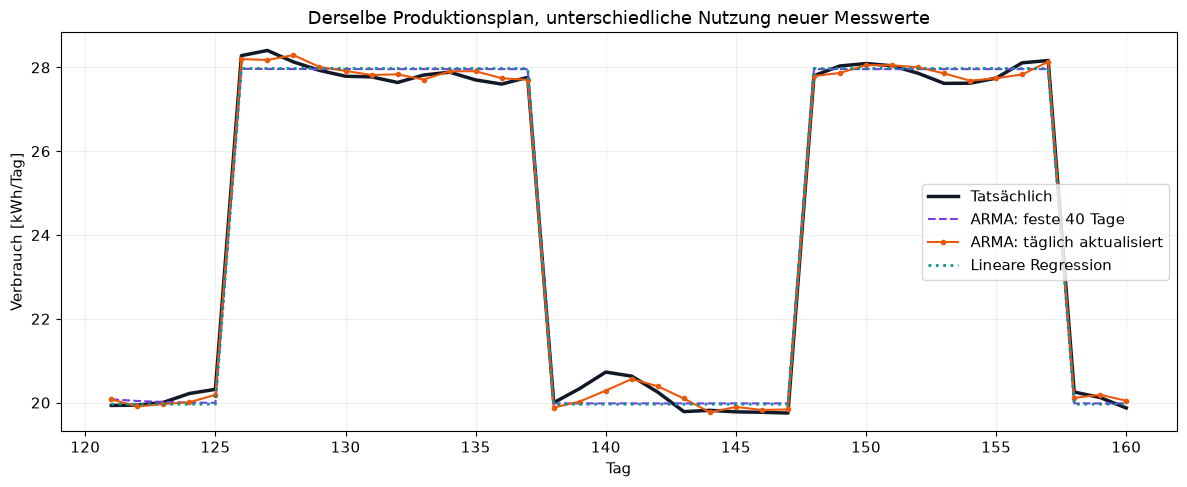

In [10]:
plt.figure(figsize=(12, 5))
plt.plot(test, color="#111827", linewidth=2.5, label="Tatsächlich")
plt.plot(prognose_fest, "--", color="#7c3aed", label="ARMA: feste 40 Tage")
plt.plot(prognose_rollend, "o-", markersize=3, color="#ea580c", label="ARMA: täglich aktualisiert")
plt.plot(prognose_regression, ":", linewidth=2, color="#0d9488", label="Lineare Regression")
plt.title("Derselbe Produktionsplan, unterschiedliche Nutzung neuer Messwerte")
plt.xlabel("Tag")
plt.ylabel("Verbrauch [kWh/Tag]")
plt.legend()
plt.tight_layout()
plt.show()

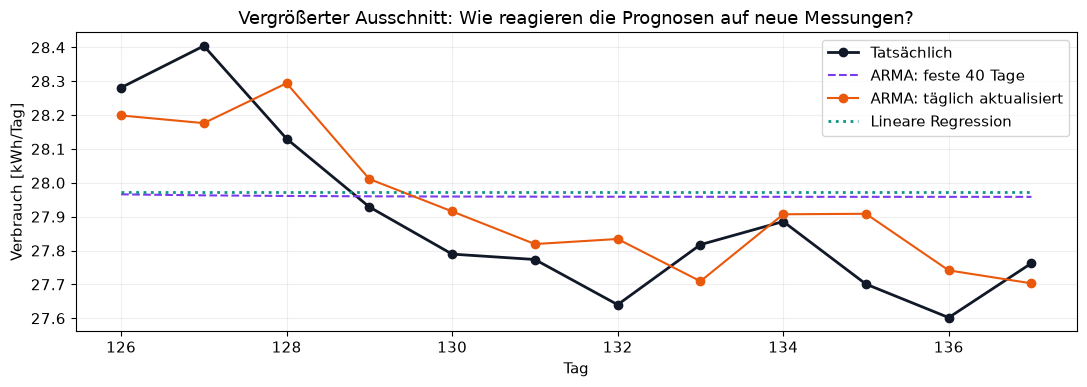

In [11]:
# Tage 126 bis 137: durchgehend Produktion, daher keine großen Plansprünge.
plt.figure(figsize=(11, 4))
plt.plot(test.loc[126:137], "o-", color="#111827", linewidth=2, label="Tatsächlich")
plt.plot(prognose_fest.loc[126:137], "--", color="#7c3aed", label="ARMA: feste 40 Tage")
plt.plot(prognose_rollend.loc[126:137], "o-", color="#ea580c", label="ARMA: täglich aktualisiert")
plt.plot(prognose_regression.loc[126:137], ":", linewidth=2, color="#0d9488", label="Lineare Regression")
plt.title("Vergrößerter Ausschnitt: Wie reagieren die Prognosen auf neue Messungen?")
plt.xlabel("Tag")
plt.ylabel("Verbrauch [kWh/Tag]")
plt.legend()
plt.tight_layout()
plt.show()

**Was sagt mir der Ausschnitt?** Die lineare Regression sagt bei gleichem Produktionsplan immer
denselben Wert vorher. Die feste ARMA-Prognose erhält ebenfalls keine neuen Verbrauchsmessungen.

Das täglich aktualisierte ARMA-Modell reagiert auf die jeweils schon beobachteten Abweichungen.
Es kann deshalb den zeitlich zusammenhängenden Schwankungen folgen. Neue Überraschungen kennt es
trotzdem nicht im Voraus; es muss nicht an jedem Tag die beste Prognose liefern.

In [12]:
vergleich = pd.DataFrame({
    "Modell": ["ARMA: feste 40 Tage", "ARMA: täglich aktualisiert", "Lineare Regression"],
    "Neue Verbrauchsmessungen verwendet": ["Nein", "Nach jeder Prognose", "Nein"],
    "MAE [kWh]": [(test-prognose_fest).abs().mean(),
                   (test-prognose_rollend).abs().mean(),
                   (test-prognose_regression).abs().mean()]
})
display(vergleich.round(3))

,Modell,Neue Verbrauchsmessungen verwendet,MAE [kWh]
0,ARMA: feste 40 Tage,Nein,0.220
1,ARMA: täglich aktualisiert,Nach jeder Prognose,0.127
2,Lineare Regression,Nein,0.221


## 9. Was vergleichen wir hier eigentlich?

**Das rollende ARMA-Modell erhält mehr Informationen:** vor jeder neuen Prognose die bis dahin
eingetroffenen echten Verbrauchswerte. Der Vergleich mit festen 40-Tage-Prognosen zeigt deshalb
auch den Nutzen dieser neuen Information, nicht nur einen Unterschied zwischen Modellarten.

Die einfache Regression verwendet ausschließlich den Plan. Würden wir ihr aktuelle Verbrauchs-Lags
als Merkmale geben, wäre das ein anderes, stärkeres Vergleichsmodell.

**MA arbeitet auch bei einer festen Prognose:** Die am Start geschätzten Schocks fließen ein.
Bei MA(1) läuft ihr direkter Beitrag nach dem ersten Schritt aus; über AR kann die Wirkung weitergehen.
Beim rollenden Vorgehen kommen immer wieder neue geschätzte Schocks hinzu.

**Merke:** `forecast(1)` sagt vorher. `append(..., refit=False)` übernimmt danach eine echte Beobachtung
und aktualisiert den Zustand. Erst der nächste `forecast(1)` nutzt diese zusätzliche Information.